## pickle

In [1]:
import pandas as pd
import pickle
from pathlib import Path

with open(Path("data/processed/dfs_clean.pkl"), "rb") as f:
    dfs = pickle.load(f)

dfs.keys()   # controllo veloce: devono esserci tutte e 9 le tabelle

dict_keys(['orders', 'items', 'payments', 'reviews', 'customers', 'products', 'sellers', 'geolocation', 'category_translation'])

## vendite e fatturato

In [2]:
# Join mirato: dell'ordine serve solo la data, per aggregare per mese.
# many_to_one + stesso len prima/dopo = nessuna riga duplicata (altrimenti il fatturato si gonfia).
items = dfs["items"]
orders = dfs["orders"]

sales = items.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

print(len(items), len(sales))  # devono essere uguali

112650 112650


In [3]:
# n_orders con nunique (un ordine ha più item), n_items con count: il rapporto dà items_per_order.
# Output: 2016-09 e 2016-12 hanno 3 e 1 ordini e la crescita % esplode (fino a +1.100.000%):
# questi mesi vanno esclusi prima di leggere qualsiasi trend.
sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M")

monthly = sales.groupby("month").agg(
    revenue=("price", "sum"),
    n_orders=("order_id", "nunique"),
    n_items=("order_id", "count"),
).reset_index()

monthly["avg_order_value"] = monthly["revenue"] / monthly["n_orders"]
monthly["items_per_order"] = monthly["n_items"] / monthly["n_orders"]
monthly["revenue_growth_pct"] = monthly["revenue"].pct_change() * 100

monthly["month"] = monthly["month"].astype(str)
print(monthly)

      month     revenue  n_orders  n_items  avg_order_value  items_per_order  \
0   2016-09      267.36         3        6        89.120000         2.000000   
1   2016-10    49507.66       308      363       160.739156         1.178571   
2   2016-12       10.90         1        1        10.900000         1.000000   
3   2017-01   120312.87       789      955       152.487795         1.210393   
4   2017-02   247303.02      1733     1951       142.702262         1.125793   
5   2017-03   374344.30      2641     3000       141.743393         1.135933   
6   2017-04   359927.23      2391     2684       150.534182         1.122543   
7   2017-05   506071.14      3660     4136       138.270803         1.130055   
8   2017-06   433038.60      3217     3583       134.609450         1.113771   
9   2017-07   498031.48      3969     4519       125.480343         1.138574   
10  2017-08   573971.68      4293     4910       133.699436         1.143722   
11  2017-09   624401.69      4243     48

In [4]:
# Il filtro sui mesi con pochi ordini (2016-09, 2016-12, 2018-09) va fatto prima di calcolare la crescita %.
# Attenzione: 2017-01 risulta confrontato con 2016-10 (mancano nov e dic), quindi la sua crescita (+143%)
# non è mese su mese.
threshold = 50  # soglia esplicita: sotto 50 ordini/mese il dato non è rappresentativo

print(monthly[monthly["n_orders"] < threshold][["month", "n_orders"]])

monthly_filtered = monthly[monthly["n_orders"] >= threshold].copy()
monthly_filtered["revenue_growth_pct"] = monthly_filtered["revenue"].pct_change() * 100

      month  n_orders
0   2016-09         3
2   2016-12         1
23  2018-09         1


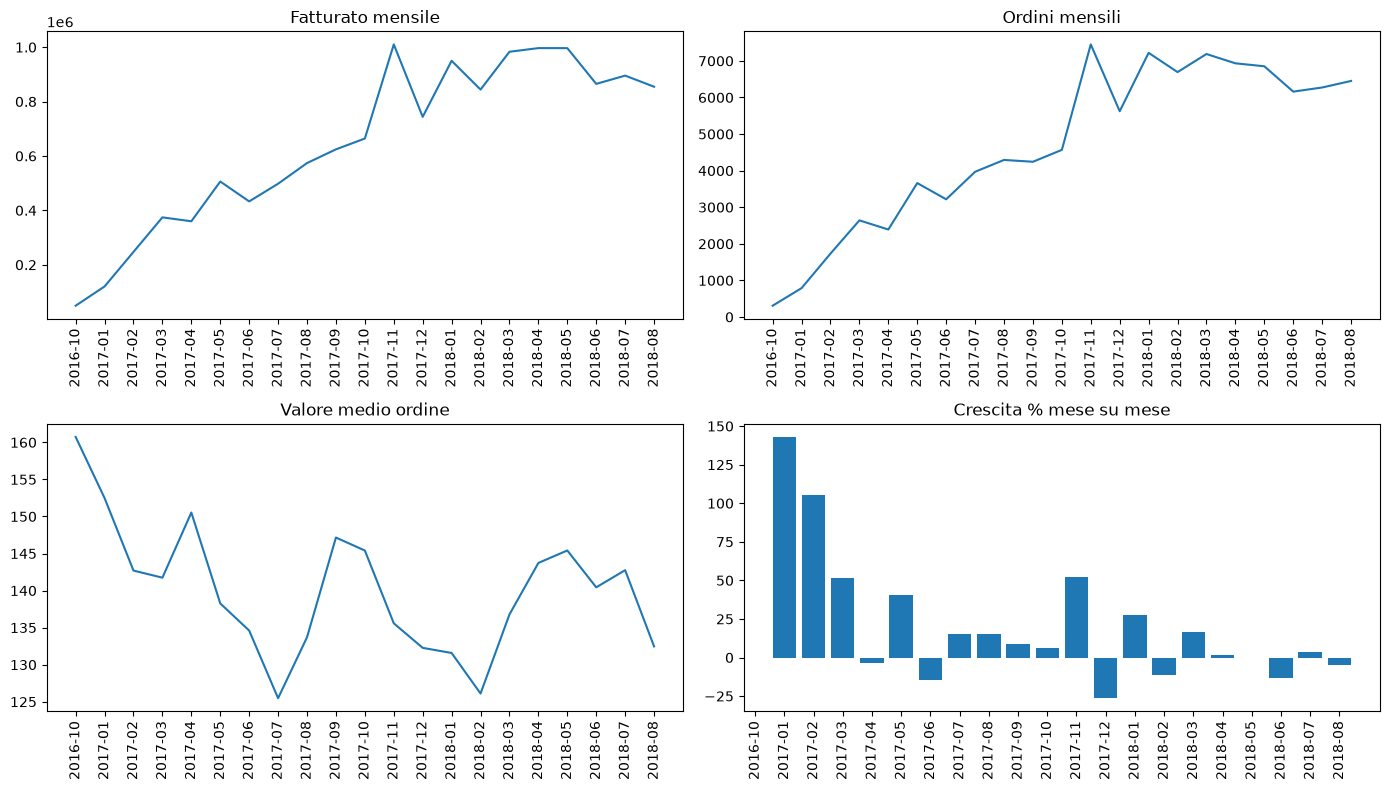

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(monthly_filtered["month"], monthly_filtered["revenue"])
axes[0, 0].set_title("Fatturato mensile")
axes[0, 0].tick_params(axis="x", rotation=90)

axes[0, 1].plot(monthly_filtered["month"], monthly_filtered["n_orders"])
axes[0, 1].set_title("Ordini mensili")
axes[0, 1].tick_params(axis="x", rotation=90)

axes[1, 0].plot(monthly_filtered["month"], monthly_filtered["avg_order_value"])
axes[1, 0].set_title("Valore medio ordine")
axes[1, 0].tick_params(axis="x", rotation=90)

axes[1, 1].bar(monthly_filtered["month"], monthly_filtered["revenue_growth_pct"])
axes[1, 1].set_title("Crescita % mese su mese")
axes[1, 1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [6]:
# Verifica: la crescita del 2017 è organica o un artefatto dei dati? Gli ordini a settimana crescono
# in modo graduale, senza salti improvvisi.
early = sales[sales["order_purchase_timestamp"] < "2017-06-01"]
weekly = early.groupby(early["order_purchase_timestamp"].dt.to_period("W")).agg(
    n_orders=("order_id", "nunique")
).reset_index()
weekly["order_purchase_timestamp"] = weekly["order_purchase_timestamp"].astype(str)
print(weekly)

   order_purchase_timestamp  n_orders
0     2016-08-29/2016-09-04         1
1     2016-09-05/2016-09-11         1
2     2016-09-12/2016-09-18         1
3     2016-09-26/2016-10-02         1
4     2016-10-03/2016-10-09       270
5     2016-10-10/2016-10-16        37
6     2016-12-19/2016-12-25         1
7     2017-01-02/2017-01-08        46
8     2017-01-09/2017-01-15        79
9     2017-01-16/2017-01-22       195
10    2017-01-23/2017-01-29       351
11    2017-01-30/2017-02-05       451
12    2017-02-06/2017-02-12       533
13    2017-02-13/2017-02-19       396
14    2017-02-20/2017-02-26       373
15    2017-02-27/2017-03-05       482
16    2017-03-06/2017-03-12       573
17    2017-03-13/2017-03-19       614
18    2017-03-20/2017-03-26       641
19    2017-03-27/2017-04-02       561
20    2017-04-03/2017-04-09       583
21    2017-04-10/2017-04-16       441
22    2017-04-17/2017-04-23       566
23    2017-04-24/2017-04-30       669
24    2017-05-01/2017-05-07       777
25    2017-0

In [7]:
# 114 giorni senza ordini, quasi tutti nel pre-lancio (set-dic 2016): solo 8 dopo il 2017,
# quindi i dati sono continui nel periodo che interessa.
daily_counts = sales.groupby(sales["order_purchase_timestamp"].dt.date).size()
full_range = pd.date_range(daily_counts.index.min(), daily_counts.index.max())
missing_days = full_range.difference(daily_counts.index)
print(len(missing_days))
print(missing_days[:20])

114
DatetimeIndex(['2016-09-06', '2016-09-07', '2016-09-08', '2016-09-09',
               '2016-09-10', '2016-09-11', '2016-09-12', '2016-09-13',
               '2016-09-14', '2016-09-16', '2016-09-17', '2016-09-18',
               '2016-09-19', '2016-09-20', '2016-09-21', '2016-09-22',
               '2016-09-23', '2016-09-24', '2016-09-25', '2016-09-26'],
              dtype='datetime64[s]', freq=None)


In [8]:
# I venditori attivi crescono in parallelo agli ordini (143 a ott-2016, 583 a mag-2017):
# la crescita viene anche dal lato offerta, non solo dalla domanda.
sellers_monthly = sales[sales["order_purchase_timestamp"] < "2017-06-01"].groupby(
    sales["order_purchase_timestamp"].dt.to_period("M")
)["seller_id"].nunique()
print(sellers_monthly)

order_purchase_timestamp
2016-09      3
2016-10    143
2016-12      1
2017-01    227
2017-02    427
2017-03    499
2017-04    506
2017-05    583
Freq: M, Name: seller_id, dtype: int64


## categorie prodotto

In [9]:
# 1.627 item (1,4%) senza categoria: schede prodotto mai compilate e categorie senza traduzione.
# Restano fuori dai confronti per categoria, non vanno corretti.
products = dfs["products"]
translation = dfs["category_translation"]

cat_sales = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id", how="left", validate="many_to_one"
).merge(
    translation, on="product_category_name", how="left", validate="many_to_one"
)

print(len(items), len(cat_sales))  # devono essere uguali
print(cat_sales["product_category_name_english"].isna().sum())  # prodotti senza categoria

112650 112650
1627


In [10]:
# Output: le prime 5 categorie fanno il 40% del fatturato (su 71). Fatturato e vendite danno classifiche
by_category = cat_sales.groupby("product_category_name_english").agg(
    revenue=("price", "sum"),
    n_sales=("order_id", "count"),
    avg_price=("price", "mean"),
    avg_freight=("freight_value", "mean"),
).reset_index()

by_category["freight_pct_of_price"] = by_category["avg_freight"] / by_category["avg_price"] * 100

top_revenue = by_category.sort_values("revenue", ascending=False).head(10)
top_sales = by_category.sort_values("n_sales", ascending=False).head(10)

print(top_revenue)
print(top_sales)

   product_category_name_english     revenue  n_sales   avg_price  \
43                 health_beauty  1258681.34     9670  130.163531   
70                 watches_gifts  1205005.68     5991  201.135984   
7                 bed_bath_table  1036988.68    11115   93.296327   
65                sports_leisure   988048.97     8641  114.344285   
15         computers_accessories   911954.32     7827  116.513903   
39               furniture_decor   729762.49     8334   87.564494   
20                    cool_stuff   635290.85     3796  167.357969   
49                    housewares   632248.66     6964   90.788148   
5                           auto   592720.11     4235  139.957523   
42                  garden_tools   485256.46     4347  111.630196   

    avg_freight  freight_pct_of_price  
43    18.879703             14.504603  
70    16.781160              8.343191  
7     18.415928             19.739178  
65    19.512500             17.064692  
15    18.821781             16.154107  


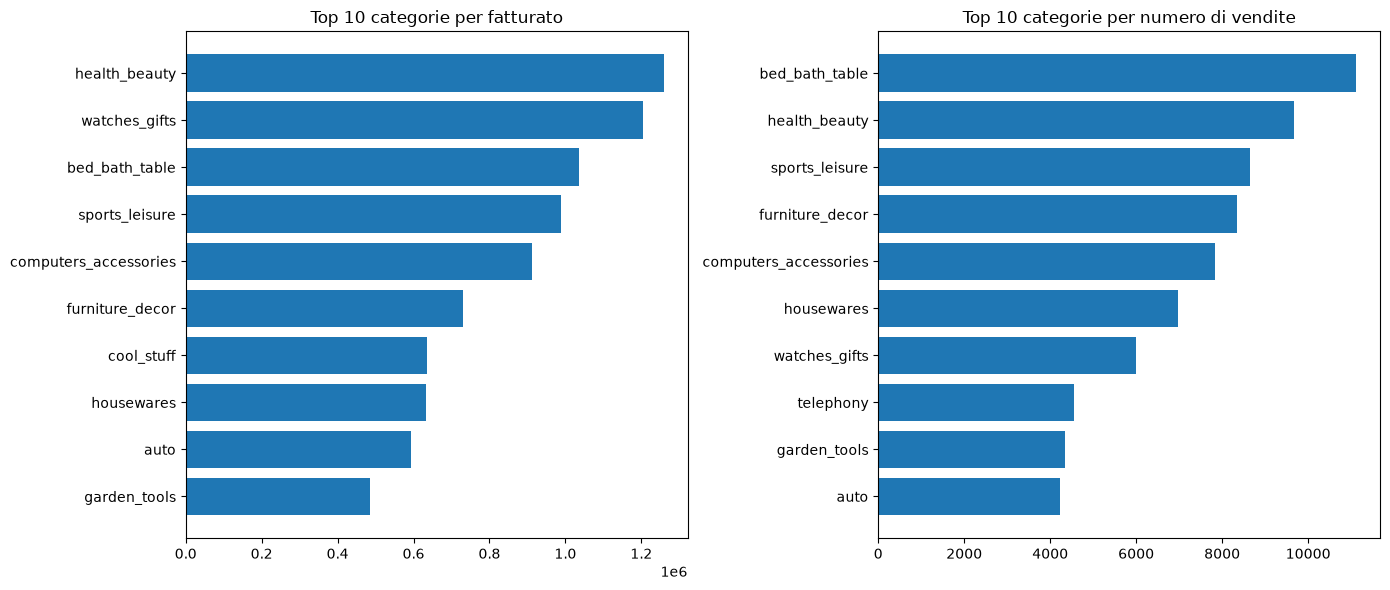

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_revenue["product_category_name_english"], top_revenue["revenue"])
axes[0].invert_yaxis()
axes[0].set_title("Top 10 categorie per fatturato")

axes[1].barh(top_sales["product_category_name_english"], top_sales["n_sales"])
axes[1].invert_yaxis()
axes[1].set_title("Top 10 categorie per numero di vendite")

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
plt.barh(top_revenue["product_category_name_english"], top_revenue["freight_pct_of_price"])
plt.gca().invert_yaxis()
plt.title("Incidenza trasporto sul prezzo (top 10 categorie per fatturato)")
plt.tight_layout()
plt.show()

## stato ordini

In [ ]:
# 97% degli ordini è "delivered": gli altri stati valgono meno dell'1% ciascuno.
status_counts = orders["order_status"].value_counts()
status_pct = orders["order_status"].value_counts(normalize=True) * 100

print(status_counts)
print(status_pct)

In [14]:
# Tasso di cancellazione mensile con soglia sul volume. Output: sempre sotto ~1,3% tranne 2016-10 (7,4%),
orders["month"] = orders["order_purchase_timestamp"].dt.to_period("M")

status_monthly = orders.groupby("month").agg(
    n_orders=("order_id", "count"),
    n_canceled=("order_status", lambda x: (x == "canceled").sum()),
).reset_index()

status_monthly["cancel_rate_pct"] = status_monthly["n_canceled"] / status_monthly["n_orders"] * 100
status_monthly = status_monthly[status_monthly["n_orders"] >= 50].copy()
status_monthly["month"] = status_monthly["month"].astype(str)

print(status_monthly)

      month  n_orders  n_canceled  cancel_rate_pct
1   2016-10       324          24         7.407407
3   2017-01       800           3         0.375000
4   2017-02      1780          17         0.955056
5   2017-03      2682          33         1.230425
6   2017-04      2404          18         0.748752
7   2017-05      3700          29         0.783784
8   2017-06      3245          16         0.493066
9   2017-07      4026          28         0.695479
10  2017-08      4331          27         0.623413
11  2017-09      4285          20         0.466744
12  2017-10      4631          26         0.561434
13  2017-11      7544          37         0.490456
14  2017-12      5673          11         0.193901
15  2018-01      7269          34         0.467740
16  2018-02      6728          73         1.085018
17  2018-03      7211          26         0.360560
18  2018-04      6939          15         0.216169
19  2018-05      6873          24         0.349192
20  2018-06      6167          

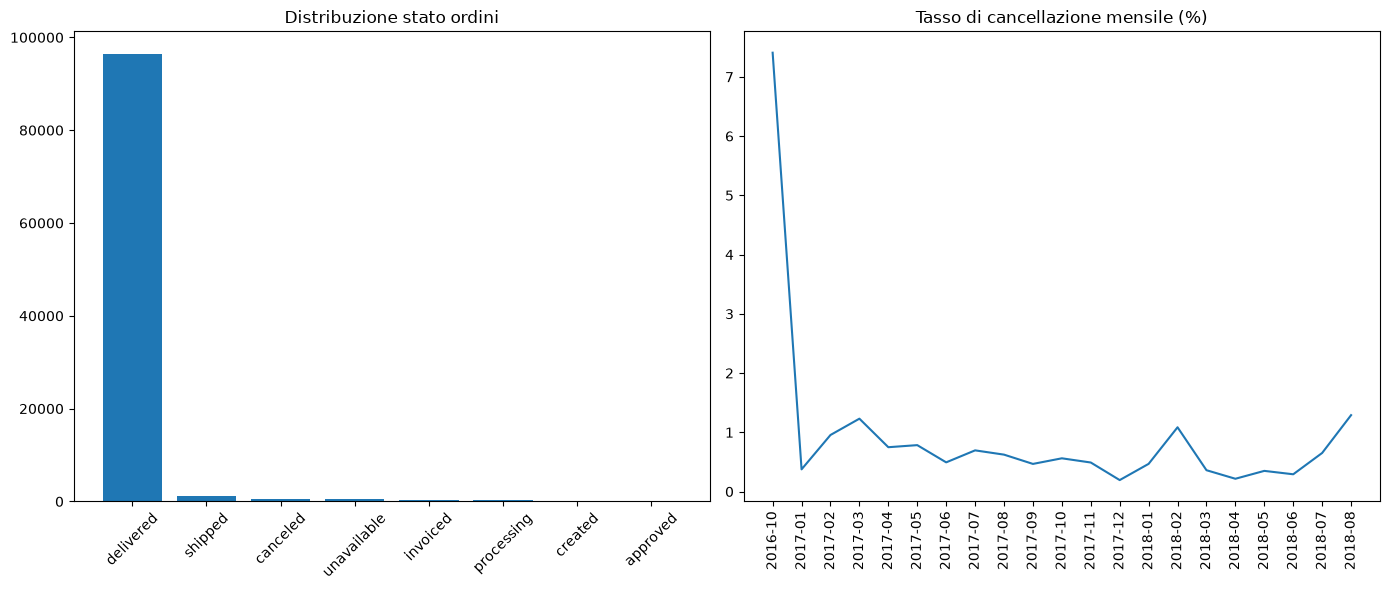

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(status_counts.index, status_counts.values)
axes[0].set_title("Distribuzione stato ordini")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(status_monthly["month"], status_monthly["cancel_rate_pct"])
axes[1].set_title("Tasso di cancellazione mensile (%)")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## pagamenti

In [16]:
# Un ordine può avere più righe di pagamento (103.886 pagamenti su 99.440 ordini):
# n_payments conta righe, non ordini.
payments = dfs["payments"]

pay = payments.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id", how="left", validate="many_to_one"
)
print(len(payments), len(pay))

103886 103886


In [17]:
# Output: la carta di credito vale il 78% del valore pagato, il boleto il 18%.
# Le rate medie hanno senso solo per la carta (3,5): gli altri metodi hanno 1 per costruzione.
type_mix = pay.groupby("payment_type").agg(
    n_payments=("order_id", "count"),
    total_value=("payment_value", "sum"),
    avg_value=("payment_value", "mean"),
    avg_installments=("payment_installments", "mean"),
).reset_index()

print(type_mix)

  payment_type  n_payments  total_value   avg_value  avg_installments
0       boleto       19784   2869361.27  145.034435          1.000000
1  credit_card       76795  12542084.19  163.319021          3.507155
2   debit_card        1529    217989.79  142.570170          1.000000
3  not_defined           3         0.00    0.000000          1.000000
4      voucher        5775    379436.87   65.703354          1.000000


In [18]:
# Rate medie della carta (solo carta, mesi con volume sufficiente): dal picco di 4,1 (mag-2017)
pay["month"] = pay["order_purchase_timestamp"].dt.to_period("M")

installments_monthly = pay[pay["payment_type"] == "credit_card"].groupby("month").agg(
    avg_installments=("payment_installments", "mean"),
    n_payments=("order_id", "count"),
).reset_index()

installments_monthly = installments_monthly[installments_monthly["n_payments"] >= 50].copy()
installments_monthly["month"] = installments_monthly["month"].astype(str)

print(installments_monthly)

      month  avg_installments  n_payments
1   2016-10          4.405512         254
3   2017-01          3.795883         583
4   2017-02          3.430678        1356
5   2017-03          3.655754        2016
6   2017-04          3.836945        1846
7   2017-05          4.088328        2853
8   2017-06          3.990662        2463
9   2017-07          3.966948        3086
10  2017-08          3.845311        3284
11  2017-09          3.724642        3283
12  2017-10          3.558456        3524
13  2017-11          3.688316        5897
14  2017-12          3.519534        4377
15  2018-01          3.222826        5520
16  2018-02          3.122216        5253
17  2018-03          3.406783        5691
18  2018-04          3.233364        5455
19  2018-05          3.363289        5497
20  2018-06          3.413671        4813
21  2018-07          3.339642        4755
22  2018-08          3.327382        4985


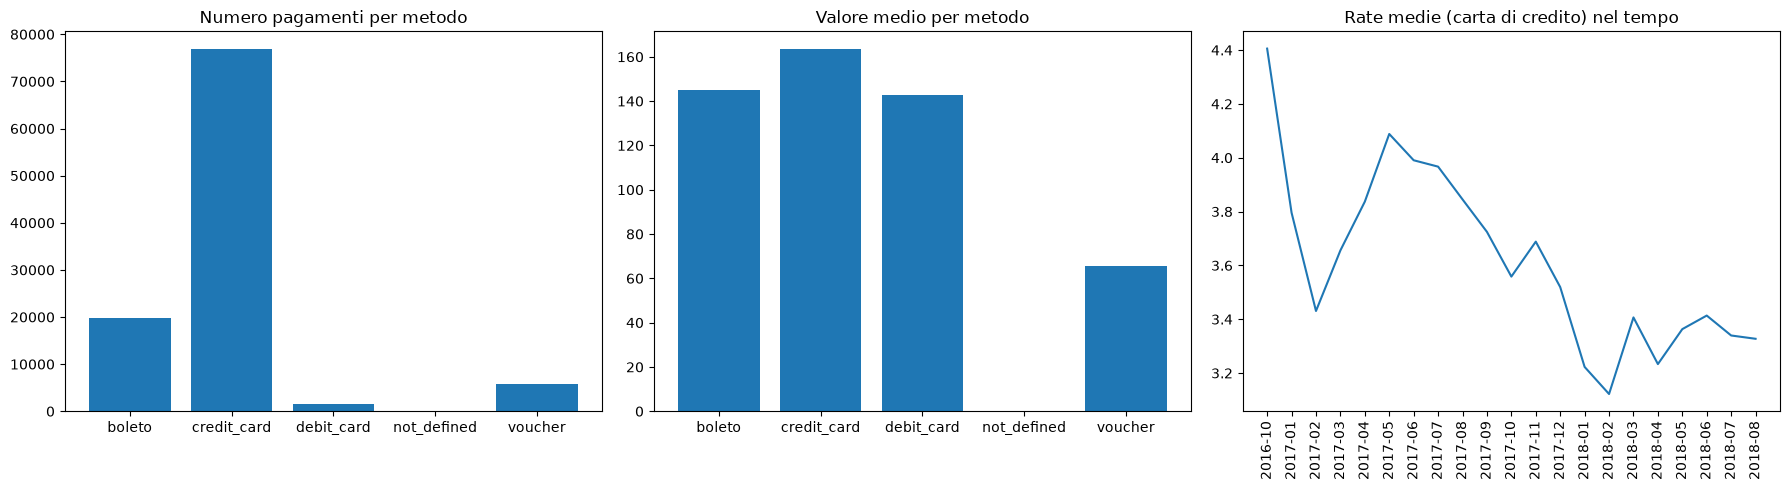

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(type_mix["payment_type"], type_mix["n_payments"])
axes[0].set_title("Numero pagamenti per metodo")

axes[1].bar(type_mix["payment_type"], type_mix["avg_value"])
axes[1].set_title("Valore medio per metodo")

axes[2].plot(installments_monthly["month"], installments_monthly["avg_installments"])
axes[2].set_title("Rate medie (carta di credito) nel tempo")
axes[2].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## recensioni

In [ ]:
# La recensione è sull'ordine, non sull'item (reviews non ha product_id né seller_id).
# 1) media per ordine: un ordine può avere più recensioni e senza questo passaggio i merge moltiplicano le righe.
# 2) in rev_items il merge con items è uno-a-molti di proposito: il voto viene copiato su ogni item dell'ordine.
# Implicazione: il punteggio per categoria è "voto medio degli ordini che la contenevano", e un ordine con
# più item pesa più volte.
reviews = dfs["reviews"]

reviews_agg = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean")
).reset_index()

rev = reviews_agg.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id", how="left", validate="many_to_one"
)

rev_items = reviews_agg.merge(
    items[["order_id", "product_id"]],
    on="order_id", how="left"
).merge(
    products[["product_id", "product_category_name"]],
    on="product_id", how="left", validate="many_to_one"
).merge(
    translation, on="product_category_name", how="left", validate="many_to_one"
)

print(len(reviews_agg), len(rev), len(rev_items))

In [21]:
# Output: distribuzione a J, 58% di voti 5 e 11,5% di voti 1.
score_dist = reviews["review_score"].value_counts().sort_index()

rev["month"] = rev["order_purchase_timestamp"].dt.to_period("M")
score_monthly = rev.groupby("month").agg(
    avg_score=("review_score", "mean"),
    n_reviews=("order_id", "count"),
).reset_index()
score_monthly = score_monthly[score_monthly["n_reviews"] >= 50].copy()
score_monthly["month"] = score_monthly["month"].astype(str)

In [ ]:
# Soglia di almeno 30 recensioni: evita medie su pochi casi (65 categorie su 71 la superano)
score_by_category = rev_items.groupby("product_category_name_english").agg(
    avg_score=("review_score", "mean"),
    n_reviews=("review_score", "count"),
).reset_index()
score_by_category = score_by_category[score_by_category["n_reviews"] >= 30]

top_category = score_by_category.sort_values("avg_score", ascending=False).head(10)
worst_category = score_by_category.sort_values("avg_score").head(10)

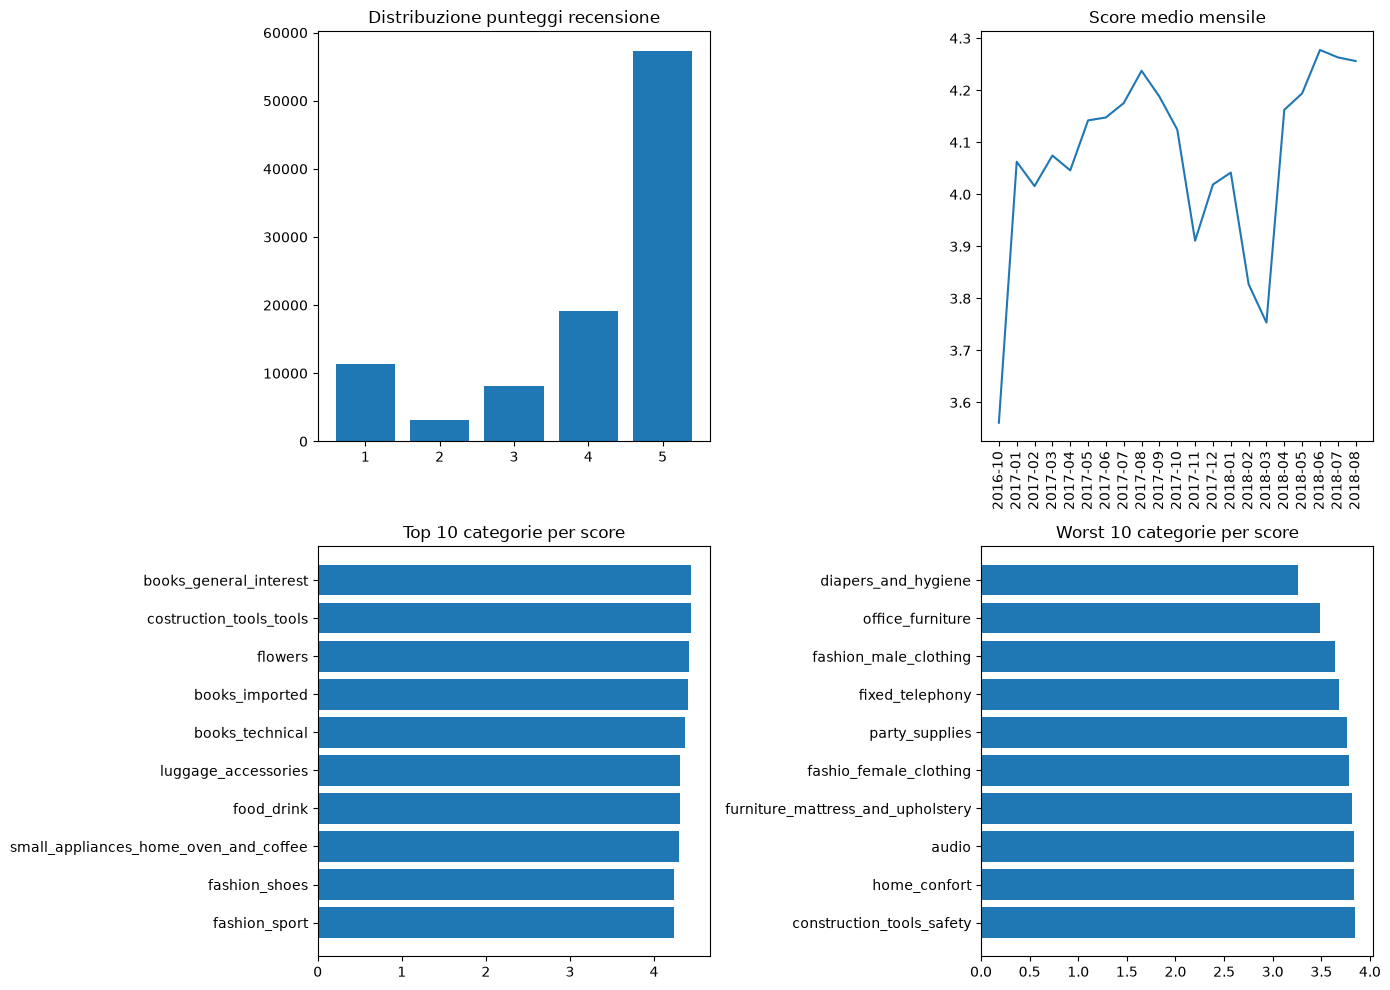

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].bar(score_dist.index.astype(str), score_dist.values)
axes[0, 0].set_title("Distribuzione punteggi recensione")

axes[0, 1].plot(score_monthly["month"], score_monthly["avg_score"])
axes[0, 1].set_title("Score medio mensile")
axes[0, 1].tick_params(axis="x", rotation=90)

axes[1, 0].barh(top_category["product_category_name_english"], top_category["avg_score"])
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("Top 10 categorie per score")

axes[1, 1].barh(worst_category["product_category_name_english"], worst_category["avg_score"])
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Worst 10 categorie per score")

plt.tight_layout()
plt.show()

## venditori

In [ ]:
# Dell'ordine serve solo la data, per contare i venditori attivi per mese.
seller_sales = items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id", how="left", validate="many_to_one"
)

print(len(items), len(seller_sales))

In [ ]:
by_seller = seller_sales.groupby("seller_id").agg(
    revenue=("price", "sum"),
    n_sales=("order_id", "count"),
).reset_index()

In [26]:
by_seller_sorted = by_seller.sort_values("revenue", ascending=False).reset_index(drop=True)
total_revenue = by_seller_sorted["revenue"].sum()

top10_pct_sellers = int(len(by_seller_sorted) * 0.10)
top10_revenue_share = by_seller_sorted.head(top10_pct_sellers)["revenue"].sum() / total_revenue * 100

print(f"Il top 10% dei venditori ({top10_pct_sellers} venditori) genera il {top10_revenue_share:.1f}% del fatturato")

Il top 10% dei venditori (309 venditori) genera il 67.5% del fatturato


In [ ]:
# Venditori attivi per mese con nunique, filtrando i mesi con pochi ordini come nel blocco A.
# Output: da 143 (ott-2016) a 1.278 (ago-2018).
seller_sales["month"] = seller_sales["order_purchase_timestamp"].dt.to_period("M")

active_sellers_monthly = seller_sales.groupby("month").agg(
    n_active_sellers=("seller_id", "nunique"),
    n_orders=("order_id", "nunique"),
).reset_index()

active_sellers_monthly = active_sellers_monthly[active_sellers_monthly["n_orders"] >= 50].copy()
active_sellers_monthly["month"] = active_sellers_monthly["month"].astype(str)

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(active_sellers_monthly["month"], active_sellers_monthly["n_active_sellers"])
plt.title("Venditori attivi per mese")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## logistica (tempi di consegna)


In [29]:
# Solo ordini consegnati: gli altri non hanno un percorso completo. .dt.days tronca le ore
# (5 ore di ritardo = 0 giorni), l'approvazione è in ore perché dura minuti.
# Output di describe(): minimi negativi (prep_time fino a -172 giorni) = date impossibili, massimi
# molto alti (209 giorni) = code lunghe. Servono un filtro sulle anomalie e le mediane al posto delle medie.
orders_delivered = orders[orders["order_status"] == "delivered"].copy()

orders_delivered["delivery_time_days"] = (
    orders_delivered["order_delivered_customer_date"] - orders_delivered["order_purchase_timestamp"]
).dt.days

orders_delivered["delay_days"] = (
    orders_delivered["order_delivered_customer_date"] - orders_delivered["order_estimated_delivery_date"]
).dt.days

orders_delivered["approval_time_hours"] = (
    orders_delivered["order_approved_at"] - orders_delivered["order_purchase_timestamp"]
).dt.total_seconds() / 3600

orders_delivered["prep_time_days"] = (
    orders_delivered["order_delivered_carrier_date"] - orders_delivered["order_purchase_timestamp"]
).dt.days

print(orders_delivered[["delivery_time_days", "delay_days", "approval_time_hours", "prep_time_days"]].describe())

       delivery_time_days    delay_days  approval_time_hours  prep_time_days
count        96470.000000  96470.000000         96464.000000    96476.000000
mean            12.093604    -11.875889            10.276767        2.736411
std              9.551380     10.182105            20.535419        3.611331
min              0.000000   -147.000000             0.000000     -172.000000
25%              6.000000    -17.000000             0.215278        1.000000
50%             10.000000    -12.000000             0.343333        2.000000
75%             15.000000     -7.000000            14.514583        4.000000
max            209.000000    188.000000           741.443611      125.000000


In [30]:
# Esclude le anomalie temporali del cleaning solo dai calcoli di durata (la tabella resta com'è):
# 174 ordini su 96.478 (0,2%), effetto trascurabile sui risultati.
valid = orders_delivered[
    (orders_delivered["prep_time_days"] >= 0) &
    (orders_delivered["delivery_time_days"] >= 0)
].copy()

print(len(orders_delivered), len(valid))

96478 96304


In [31]:
# Output: mediana di consegna 10 giorni. Solo il 6,8% arriva dopo la stima e in
# L'approvazione ha mediana 0,3 ore ma il 17,5% supera le 24 ore: una parte degli ordini ha approvazioni lente.
pct_late = (valid["delay_days"] > 0).mean() * 100
print(f"Percentuale ordini in ritardo: {pct_late:.1f}%")

print(valid[["delivery_time_days", "approval_time_hours", "prep_time_days"]].median())

Percentuale ordini in ritardo: 6.8%
delivery_time_days     10.000000
approval_time_hours     0.343333
prep_time_days          2.000000
dtype: float64


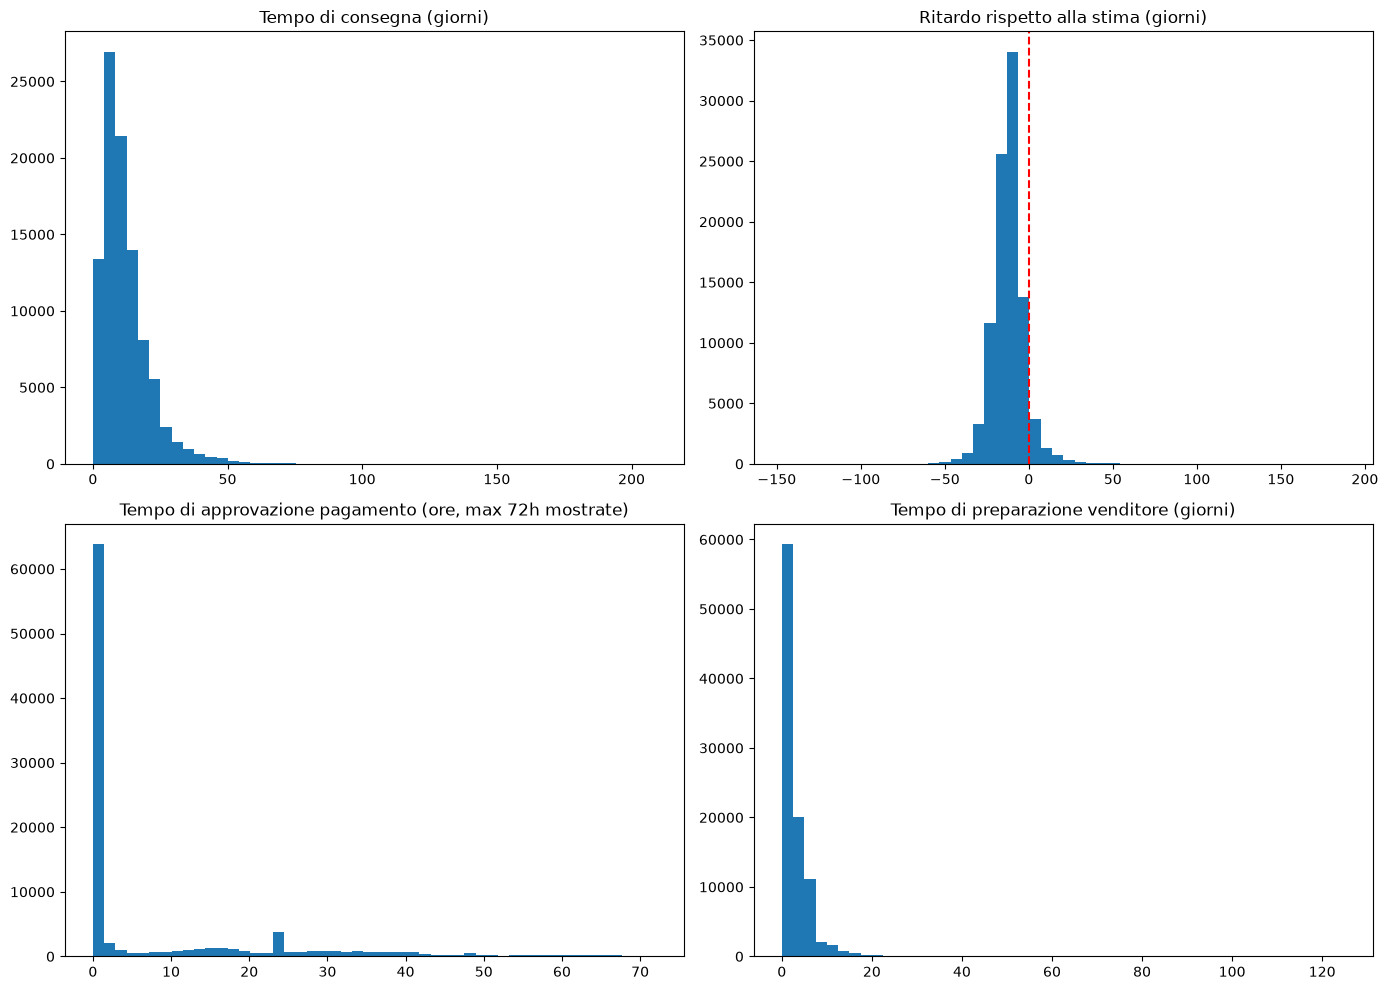

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(valid["delivery_time_days"], bins=50)
axes[0, 0].set_title("Tempo di consegna (giorni)")

axes[0, 1].hist(valid["delay_days"], bins=50)
axes[0, 1].set_title("Ritardo rispetto alla stima (giorni)")
axes[0, 1].axvline(0, color="red", linestyle="--")

axes[1, 0].hist(valid["approval_time_hours"], bins=50, range=(0, 72))
axes[1, 0].set_title("Tempo di approvazione pagamento (ore, max 72h mostrate)")

axes[1, 1].hist(valid["prep_time_days"], bins=50)
axes[1, 1].set_title("Tempo di preparazione venditore (giorni)")

plt.tight_layout()
plt.show()

## geografia e logistica

In [ ]:
# geolocation ha ~1 milione di righe per pochi CAP: va ridotta a una riga per CAP (media di lat/lng),
# altrimenti il join moltiplica gli ordini. Due copie rinominate: servono le coordinate sia del cliente
# sia del venditore nella stessa tabella.
geo = dfs["geolocation"]
customers = dfs["customers"]
sellers = dfs["sellers"]

geo_agg = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean"),
).reset_index()

geo_cust = geo_agg.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "lat": "customer_lat", "lng": "customer_lng",
})
geo_sell = geo_agg.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "lat": "seller_lat", "lng": "seller_lng",
})

In [ ]:
# Il merge con items porta la tabella a livello di item (110.002 righe contro 96.304 ordini):
# per contare ordini serve nunique. Parte da valid (non da orders_delivered): le durate di questo blocco
# (tempi per stato, scatter) escludono così le date impossibili del cleaning, come nel blocco G.
# Costo: 174 ordini (0,15% del fatturato) escono anche da fatturato e flussi, trascurabile.
geo_orders = (
    valid
    .merge(customers[["customer_id", "customer_zip_code_prefix", "customer_state"]],
           on="customer_id", how="left", validate="many_to_one")
    .merge(items[["order_id", "seller_id", "price"]], on="order_id", how="left")
    .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]],
           on="seller_id", how="left", validate="many_to_one")
    .merge(geo_cust, on="customer_zip_code_prefix", how="left", validate="many_to_one")
    .merge(geo_sell, on="seller_zip_code_prefix", how="left", validate="many_to_one")
)

print(len(valid), len(geo_orders))  # item-level, quindi geo_orders >= valid

In [35]:
# Output: SP vale il 38% del fatturato e consegna in media in 8 giorni; gli stati del Nord impiegano
# più del triplo (PA 23, AM 26, AP e RR 28 giorni). Con pochi ordini (RR 41, AP 67) le medie sono instabili.
by_state = geo_orders.groupby("customer_state").agg(
    revenue=("price", "sum"),
    n_orders=("order_id", "nunique"),
    avg_delivery_days=("delivery_time_days", "mean"),
).reset_index().sort_values("revenue", ascending=False)

print(by_state)

   customer_state     revenue  n_orders  avg_delivery_days
25             SP  5067633.16     40501           8.259663
18             RJ  1759651.13     12350          14.688821
10             MG  1552481.83     11354          11.514091
22             RS   728897.47      5345          14.708299
17             PR   666063.51      4923          11.480793
23             SC   507012.13      3546          14.517208
4              BA   493584.14      3256          18.774640
6              DF   296498.41      2080          12.501486
8              GO   282836.70      1957          14.948177
7              ES   268643.45      1995          15.192809
15             PE   251889.49      1593          17.792096
5              CE   219757.38      1279          20.537167
13             PA   174470.59       946          23.301708
12             MT   152191.62       886          17.508197
9              MA   117009.38       717          21.203750
11             MS   115429.97       701          15.1072

In [36]:
# Haversine: distanza sulla sfera tra due coppie lat/lng (Pitagora sulle coordinate non vale,
# i gradi di longitudine si accorciano allontanandosi dall'equatore).
# È una distanza in linea d'aria tra centri di CAP: indicatore relativo, non i km percorsi.
# Output: mediana 432 km; correlazione con i giorni di consegna 0,39: la distanza spiega solo in parte i tempi.
import numpy as np

def haversine(lat1, lng1, lat2, lng2):
    R = 6371
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

geo_orders["distance_km"] = haversine(
    geo_orders["customer_lat"], geo_orders["customer_lng"],
    geo_orders["seller_lat"], geo_orders["seller_lng"]
)

print(geo_orders["distance_km"].describe())

count    109660.000000
mean        595.896263
std         587.306013
min           0.000000
25%         185.201550
50%         431.810666
75%         791.335632
max        3399.190906
Name: distance_km, dtype: float64


In [37]:
# Output: SP -> SP è il 32% degli item: la logistica ruota attorno a San Paolo (venditori concentrati lì).
# size() conta righe, quindi item e non ordini distinti.
flows = geo_orders.groupby(["seller_state", "customer_state"]).size().reset_index(name="n_orders")
flows = flows.sort_values("n_orders", ascending=False).head(15)
print(flows)

    seller_state customer_state  n_orders
410           SP             SP     35425
403           SP             RJ      9403
395           SP             MG      8567
407           SP             RS      4134
402           SP             PR      3609
278           PR             SP      3340
169           MG             SP      2902
408           SP             SC      2709
389           SP             BA      2626
154           MG             MG      1669
393           SP             GO      1657
392           SP             ES      1621
391           SP             DF      1565
376           SC             SP      1487
304           RJ             SP      1470


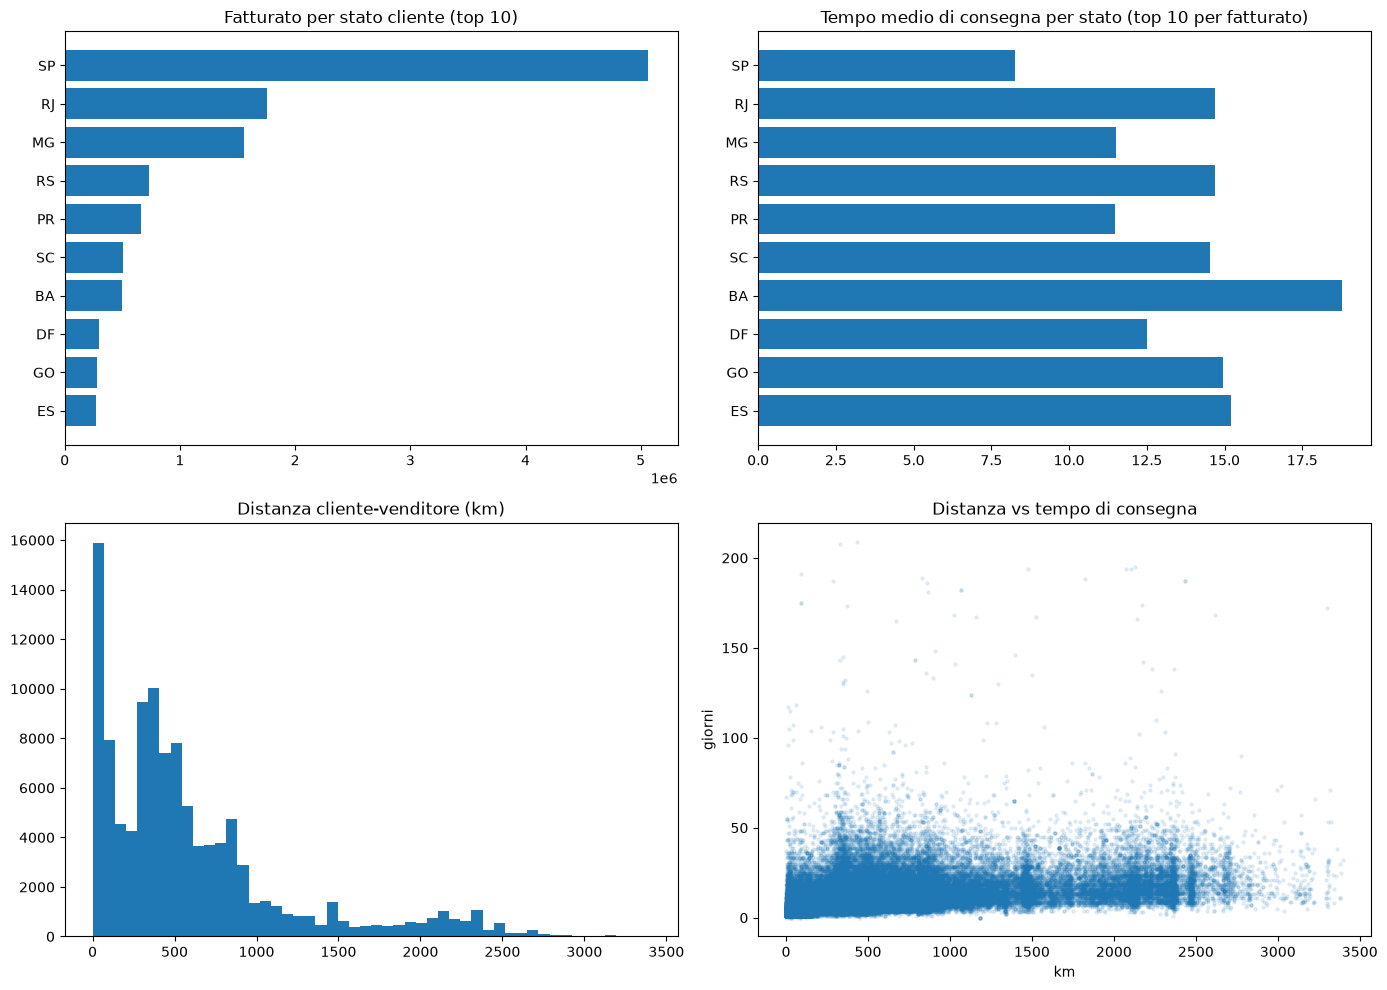

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

top_states = by_state.head(10)
axes[0, 0].barh(top_states["customer_state"], top_states["revenue"])
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("Fatturato per stato cliente (top 10)")

axes[0, 1].barh(top_states["customer_state"], top_states["avg_delivery_days"])
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("Tempo medio di consegna per stato (top 10 per fatturato)")

valid_dist = geo_orders.dropna(subset=["distance_km"])
axes[1, 0].hist(valid_dist["distance_km"], bins=50)
axes[1, 0].set_title("Distanza cliente-venditore (km)")

axes[1, 1].scatter(valid_dist["distance_km"], valid_dist["delivery_time_days"], alpha=0.1, s=5)
axes[1, 1].set_title("Distanza vs tempo di consegna")
axes[1, 1].set_xlabel("km")
axes[1, 1].set_ylabel("giorni")

plt.tight_layout()
plt.show()

## clienti e RFM


In [39]:
# Si lavora su customer_unique_id (la persona), non su customer_id che cambia a ogni ordine:
# altrimenti ogni acquisto sembrerebbe un cliente nuovo e il riacquisto sparirebbe. Solo ordini consegnati.
cust_orders = (
    items
    .merge(orders[["order_id", "customer_id", "order_purchase_timestamp", "order_status"]],
           on="order_id", how="left", validate="many_to_one")
    .merge(customers[["customer_id", "customer_unique_id"]],
           on="customer_id", how="left", validate="many_to_one")
)

cust_orders = cust_orders[cust_orders["order_status"] == "delivered"].copy()
print(len(cust_orders))

110197


In [40]:
# snapshot_date = ultimo acquisto + 1 giorno (dati storici: non si può usare "oggi").
# frequency con nunique perché un ordine ha più item. Output: 93.358 clienti, quasi tutti a 1 ordine,
# spesa mediana 90 R$ con coda molto lunga (massimo 13.440).
snapshot_date = cust_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = cust_orders.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum"),
).reset_index()

rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

print(rfm[["recency", "frequency", "monetary"]].describe())

            recency     frequency      monetary
count  93358.000000  93358.000000  93358.000000
mean     237.941773      1.033420    141.621480
std      152.591453      0.209097    215.694014
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      219.000000      1.000000     89.730000
75%      346.000000      1.000000    154.737500
max      714.000000     15.000000  13440.000000


In [ ]:
# Output: solo il 3% dei clienti ha riacquistato: è il dato centrale del progetto e il motivo per cui
# retention e cohort non sono state tenute, e per cui la frequency pesa poco nei segmenti.
repeat_rate = (rfm["frequency"] > 1).mean() * 100
print(f"Clienti con più di un ordine: {repeat_rate:.1f}%")

In [41]:
# La frequency non si divide in quartili (97% dei clienti a 1 ordine: qcut darebbe errore): scala manuale,
# con il valore 3 che non viene mai assegnato (1 ordine = 1, 2 = 2, 3 o più = 4). Recency invertita: 4 = comprato di recente.
# Output: solo lo 0,65% dei clienti è "top": i segmenti dipendono soprattutto da recency e monetary.
# Le soglie dei segmenti (10, 7, 5) sono scelte arbitrarie.
rfm["r_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["f_score"] = rfm["frequency"].apply(lambda x: 4 if x >= 3 else x)
rfm["m_score"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

rfm["rfm_sum"] = rfm["r_score"] + rfm["f_score"] + rfm["m_score"]

def segment(score):
    if score >= 10: return "top"
    elif score >= 7: return "medio-alto"
    elif score >= 5: return "medio-basso"
    else: return "basso"

rfm["segment"] = rfm["rfm_sum"].apply(segment)

print(rfm["segment"].value_counts())

segment
medio-basso    40162
medio-alto     35212
basso          17376
top              608
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(rfm["monetary"], bins=50)
axes[0].set_title("Distribuzione monetary (spesa totale per cliente)")

segment_order = rfm["segment"].value_counts()
axes[1].bar(segment_order.index, segment_order.values)
axes[1].set_title("Clienti per segmento RFM")

plt.tight_layout()
plt.show()

## export per Power BI


In [ ]:
# Rilegge il pickle da zero: nell'EDA alcune tabelle hanno ricevuto colonne di lavoro (es. "month" in orders)
# che in Power BI vanno ricalcolate con DAX, non importate già pronte.
# Si esportano le tabelle separate (il modello relazionale lo ricostruisce Power BI), non il dataset largo dell'EDA.
with open(Path("data/processed/dfs_clean.pkl"), "rb") as f:
    export = pickle.load(f)

out_dir = Path("data/processed/csv")
out_dir.mkdir(parents=True, exist_ok=True)

# geolocation: una riga per CAP (media lat/lng), come nell'EDA. Serve una chiave unica per la relazione
# molti-a-uno con customers e sellers, e riduce il file da ~1 milione di righe a poche migliaia.
export["geolocation"] = (
    export["geolocation"].groupby("geolocation_zip_code_prefix")
    .agg(geolocation_lat=("geolocation_lat", "mean"), geolocation_lng=("geolocation_lng", "mean"))
    .reset_index()
)

for name, df in export.items():
    df.to_csv(out_dir / f"{name}.csv", index=False, encoding="utf-8-sig")  # utf-8-sig: accenti corretti anche in Excel
    print(f"{name}: {len(df)} righe, {df.shape[1]} colonne")